# 04. Segunda etapa de modelagem — Random Forest

Este notebook implementa uma segunda etapa deliberadamente simples, mantendo a mesma lógica de avaliação do baseline.

## Objetivos
- **Regressão:** comparar Ridge com `RandomForestRegressor`.
- **Classificação:** comparar Regressão Logística com `RandomForestClassifier`.

## Por que Random Forest nesta etapa?
É um próximo passo natural após modelos lineares porque:
- captura relações não lineares;
- captura interações entre prazo, execução e financeiro;
- exige pouca preparação;
- é relativamente robusto;
- permite interpretação por importância das variáveis.

## Regras preservadas
- split temporal por contrato;
- pesos por contrato;
- exclusão de leakage;
- classificação apenas antes do vencimento do prazo;
- threshold escolhido somente na validação;
- teste reservado para avaliação final;
- análise complementar por contrato em horizonte aproximadamente fixo.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_columns", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


## 1. Carregamento e compatibilidade com V1/V2

In [2]:
def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "processed").exists():
            return candidate
    return current

PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
METRICS_DIR = ARTIFACTS_DIR / "metrics"
PREDICTIONS_DIR = ARTIFACTS_DIR / "predictions"

for folder in [METRICS_DIR, PREDICTIONS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

candidate_paths = [
    PROCESSED_DIR / "dataset_modelagem_obras_snapshots_v2.csv",
    PROCESSED_DIR / "dataset_modelagem_obras_snapshots.csv",
    PROJECT_ROOT / "dataset_modelagem_obras_snapshots_v2.csv",
    PROJECT_ROOT / "dataset_modelagem_obras_snapshots.csv",
    Path("/mnt/data/dataset_modelagem_obras_snapshots_v2.csv"),
    Path("/mnt/data/dataset_modelagem_obras_snapshots.csv"),
]

DATASET_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATASET_PATH is None:
    raise FileNotFoundError("Dataset de snapshots não encontrado.")

df = pd.read_csv(DATASET_PATH, low_memory=False)

for c in [
    "data_corte", "data_os", "data_termino_original",
    "data_termino_vigente_corte", "data_conclusao_controle",
    "data_termino_vigente_final_controle",
]:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors="coerce")

required_base = [
    "id_contrato", "data_corte", "target_dias_atraso",
    "target_atraso", "flag_apto_treino",
    "dias_restantes_prazo_vigente", "data_conclusao_controle",
]
missing = [c for c in required_base if c not in df.columns]
if missing:
    raise ValueError(f"Colunas obrigatórias ausentes: {missing}")

# Compatibilidade com V1: cria peso por contrato.
if "sample_weight_contrato" not in df.columns:
    counts = df[df["flag_apto_treino"].eq(1)].groupby("id_contrato").size()
    df["sample_weight_contrato_raw"] = df["id_contrato"].map(
        lambda cid: 1.0 / counts[cid] if cid in counts.index else np.nan
    )
    mean_w = df.loc[
        df["flag_apto_treino"].eq(1), "sample_weight_contrato_raw"
    ].mean()
    df["sample_weight_contrato"] = df["sample_weight_contrato_raw"] / mean_w

# Compatibilidade com V1: cria split temporal por contrato.
if "split_modelagem" not in df.columns:
    contratos_rotulados = (
        df[df["flag_apto_treino"].eq(1)]
        .groupby("id_contrato")["data_conclusao_controle"]
        .max()
        .dropna()
        .sort_values()
    )

    n = len(contratos_rotulados)
    n_train = int(np.floor(n * 0.70))
    n_val = int(np.floor(n * 0.15))

    ids_train = set(contratos_rotulados.index[:n_train])
    ids_val = set(contratos_rotulados.index[n_train:n_train+n_val])
    ids_test = set(contratos_rotulados.index[n_train+n_val:])

    df["split_contrato_temporal"] = "scoring"
    df.loc[df["id_contrato"].isin(ids_train), "split_contrato_temporal"] = "train"
    df.loc[df["id_contrato"].isin(ids_val), "split_contrato_temporal"] = "validation"
    df.loc[df["id_contrato"].isin(ids_test), "split_contrato_temporal"] = "test"

    df["split_modelagem"] = np.where(
        df["flag_apto_treino"].eq(1),
        df["split_contrato_temporal"],
        "nao_supervisionado",
    )

if "split_contrato_temporal" not in df.columns:
    contract_split = (
        df[df["split_modelagem"].isin(["train", "validation", "test"])]
        .drop_duplicates("id_contrato")
        .set_index("id_contrato")["split_modelagem"]
        .to_dict()
    )
    df["split_contrato_temporal"] = (
        df["id_contrato"].map(contract_split).fillna("scoring")
    )

print("Dataset:", DATASET_PATH)
print("Shape:", df.shape)
print("Contratos:", df["id_contrato"].nunique())
display(df["split_modelagem"].value_counts().rename("snapshots").to_frame())


Dataset: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\processed\dataset_modelagem_obras_snapshots.csv
Shape: (1435, 47)
Contratos: 78


,snapshots
split_modelagem,
train,621
nao_supervisionado,401
test,261
validation,152


## 2. Amostras supervisionadas

In [3]:
valid_splits = ["train", "validation", "test"]

model_data = df[
    df["flag_apto_treino"].eq(1)
    & df["split_modelagem"].isin(valid_splits)
].copy()

reg_data = model_data.copy()

# Para classificação, excluir snapshots em que o prazo já venceu.
clf_data = model_data[
    model_data["dias_restantes_prazo_vigente"].ge(0)
].copy()

summary = pd.DataFrame({
    "amostra": ["regressao", "classificacao_pre_prazo"],
    "snapshots": [len(reg_data), len(clf_data)],
    "contratos": [
        reg_data["id_contrato"].nunique(),
        clf_data["id_contrato"].nunique(),
    ],
    "taxa_atraso": [
        reg_data["target_atraso"].mean(),
        clf_data["target_atraso"].mean(),
    ],
})
display(summary)


,amostra,snapshots,contratos,taxa_atraso
0,regressao,1034,59,0.8395
1,classificacao_pre_prazo,720,59,0.7764


## 3. Features

In [4]:
numeric_candidates = [
    "valor_total_contrato",
    "prazo_original_dias",
    "dias_desde_os",
    "dias_restantes_prazo_vigente",
    "pct_prazo_consumido",
    "qtd_aditivos_prazo",
    "dias_aditados_acumulados",
    "pct_dias_aditados_sobre_prazo_original",
    "qtd_aditivos_valor",
    "pct_parcelas_concluidas_vs_previstas",
    "atraso_medio_parcelas_dias",
    "atraso_maximo_parcelas_dias",
    "pct_parcelas_atrasadas",
    "atraso_medio_parcelas_90d",
    "qtd_parcelas_atrasadas_90d",
    "pct_financeiro_liberado",
    "gap_prazo_financeiro",
    "atraso_medio_liberacao_dias",
    "atraso_maximo_liberacao_dias",
    # V2 enriquecida
    "recent_atraso_medio_parcelas_30d",
    "recent_atraso_medio_parcelas_90d",
    "recent_pct_parcelas_atrasadas_90d",
    "delta_atraso_90d_vs_historico",
    "dias_desde_ultima_parcela_concluida",
    "recent_atraso_medio_liberacao_90d",
    "dias_desde_ultima_liberacao",
    "gap_prazo_execucao",
    "pressao_tempo_financeiro",
    "pressao_tempo_execucao",
    "mes_sin",
    "mes_cos",
]

numeric_features = [c for c in numeric_candidates if c in df.columns]

if "classificacao_contrato_agrupada" in df.columns:
    categorical_features = ["classificacao_contrato_agrupada"]
elif "classificacao_contrato" in df.columns:
    categorical_features = ["classificacao_contrato"]
else:
    categorical_features = []

features = numeric_features + categorical_features

print("Features numéricas:", len(numeric_features))
print("Features categóricas:", len(categorical_features))
print("Total:", len(features))


Features numéricas: 18
Features categóricas: 1
Total: 19


## 4. Preprocessamento

In [5]:
tree_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
])

linear_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

tree_preprocessing = ColumnTransformer(
    transformers=[
        ("numeric", tree_numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)

linear_preprocessing = ColumnTransformer(
    transformers=[
        ("numeric", linear_numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)

def split_xy(data, split):
    part = data[data["split_modelagem"].eq(split)].copy()
    X = part[features]
    y_reg = part["target_dias_atraso"].astype(float)
    y_clf = part["target_atraso"].astype(int)
    w = part["sample_weight_contrato"].astype(float)
    return part, X, y_reg, y_clf, w


# Parte A — Regressão

In [6]:
reg_train, Xr_train, yr_train, _, wr_train = split_xy(reg_data, "train")
reg_val, Xr_val, yr_val, _, wr_val = split_xy(reg_data, "validation")
reg_test, Xr_test, yr_test, _, wr_test = split_xy(reg_data, "test")

regression_models = {
    "dummy_mediana": Pipeline([
        ("preprocessing", clone(linear_preprocessing)),
        ("model", DummyRegressor(strategy="median")),
    ]),
    "ridge": Pipeline([
        ("preprocessing", clone(linear_preprocessing)),
        ("model", Ridge(alpha=10.0)),
    ]),
    "random_forest": Pipeline([
        ("preprocessing", clone(tree_preprocessing)),
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=8,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}


In [7]:
def regression_metrics(y_true, y_pred, sample_weight=None):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "mae_ponderado": mean_absolute_error(
            y_true, y_pred, sample_weight=sample_weight
        ),
        "mae_sem_peso": mean_absolute_error(y_true, y_pred),
        "medae_sem_peso": median_absolute_error(y_true, y_pred),
        "rmse_ponderado": mean_squared_error(
            y_true, y_pred, sample_weight=sample_weight
        ) ** 0.5,
        "r2_ponderado": r2_score(
            y_true, y_pred, sample_weight=sample_weight
        ),
        "pct_erro_ate_30d_ponderado": np.average(
            np.abs(y_true - y_pred) <= 30,
            weights=sample_weight,
        ),
        "erro_medio_assinado_ponderado": np.average(
            y_pred - y_true,
            weights=sample_weight,
        ),
    }

regression_results = []
fitted_regression = {}

for name, model in regression_models.items():
    model.fit(Xr_train, yr_train, model__sample_weight=wr_train)
    fitted_regression[name] = model

    for split_name, X_, y_, w_ in [
        ("validation", Xr_val, yr_val, wr_val),
        ("test", Xr_test, yr_test, wr_test),
    ]:
        pred = np.maximum(0, model.predict(X_))
        row = {"modelo": name, "split": split_name}
        row.update(regression_metrics(y_, pred, w_))
        regression_results.append(row)

regression_metrics_df = pd.DataFrame(regression_results)

display(
    regression_metrics_df
    .sort_values(["split", "mae_ponderado"])
    .reset_index(drop=True)
)


,modelo,split,mae_ponderado,mae_sem_peso,medae_sem_peso,rmse_ponderado,r2_ponderado,pct_erro_ate_30d_ponderado,erro_medio_assinado_ponderado
0,random_forest,test,97.8732,91.9147,60.1106,139.6237,0.3028,0.1683,1.4015
1,ridge,test,119.3280,130.9025,113.0000,156.2491,0.1269,0.1649,-23.3439
2,dummy_mediana,test,169.5000,190.8161,136.0000,229.4387,-0.8827,0.0000,-157.1000
3,ridge,validation,88.8291,216.9372,131.9584,152.5088,0.5094,0.2859,-23.5623
4,random_forest,validation,113.5985,316.2283,346.3581,196.2064,0.1879,0.2576,-45.8312
5,dummy_mediana,validation,143.2500,425.3947,703.0000,256.4483,-0.3873,0.1250,-135.5000


### Seleção na validação e avaliação final

In [8]:
best_reg_name = (
    regression_metrics_df[
        regression_metrics_df["split"].eq("validation")
    ]
    .sort_values("mae_ponderado")
    .iloc[0]["modelo"]
)
best_reg = fitted_regression[best_reg_name]

print("Melhor modelo na validação:", best_reg_name)

reg_test_eval = reg_test.copy()
reg_test_eval["pred_dias_atraso"] = np.maximum(
    0, best_reg.predict(Xr_test)
)
reg_test_eval["erro_abs"] = np.abs(
    reg_test_eval["target_dias_atraso"]
    - reg_test_eval["pred_dias_atraso"]
)

display(
    reg_test_eval[
        [
            "id_contrato", "data_corte", "faixa_antecedencia",
            "target_dias_atraso", "pred_dias_atraso", "erro_abs"
        ]
    ].head(15)
)


Melhor modelo na validação: ridge


,id_contrato,data_corte,faixa_antecedencia,target_dias_atraso,pred_dias_atraso,erro_abs
612,158,2021-09-23,>=180d,313.0000,0.0000,313.0000
613,158,2021-09-30,>=180d,313.0000,0.0000,313.0000
614,158,2021-10-31,>=180d,313.0000,0.0000,313.0000
615,158,2021-11-30,>=180d,313.0000,43.8694,269.1306
616,158,2021-12-31,>=180d,313.0000,15.0734,297.9266
617,158,2022-01-31,>=180d,313.0000,13.2588,299.7412
618,158,2022-02-28,>=180d,313.0000,32.3853,280.6147
619,158,2022-03-31,>=180d,313.0000,49.8745,263.1255
620,158,2022-04-30,>=180d,313.0000,63.5847,249.4153
621,158,2022-05-31,>=180d,313.0000,101.3006,211.6994


In [9]:
horizon_reg = (
    reg_test_eval
    .groupby("faixa_antecedencia", observed=True)
    .apply(
        lambda g: pd.Series({
            "snapshots": len(g),
            "contratos": g["id_contrato"].nunique(),
            "mae_ponderado": np.average(
                g["erro_abs"],
                weights=g["sample_weight_contrato"],
            ),
            "mediana_erro_abs": g["erro_abs"].median(),
        })
    )
    .reset_index()
)

display(horizon_reg)


,faixa_antecedencia,snapshots,contratos,mae_ponderado,mediana_erro_abs
0,30-89d,36.0000,10.0000,123.0994,165.7032
1,90-179d,24.0000,9.0000,133.6687,147.1170
2,<30d,108.0000,10.0000,122.5317,112.1015
3,>=180d,93.0000,6.0000,107.1964,106.2345


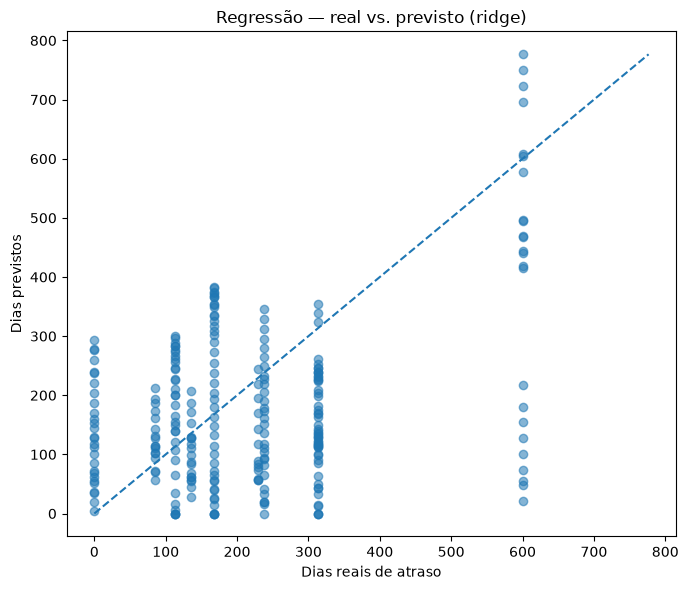

In [10]:
plt.figure(figsize=(7, 6))
plt.scatter(
    reg_test_eval["target_dias_atraso"],
    reg_test_eval["pred_dias_atraso"],
    alpha=0.55,
)
mx = max(
    reg_test_eval["target_dias_atraso"].max(),
    reg_test_eval["pred_dias_atraso"].max(),
)
plt.plot([0, mx], [0, mx], linestyle="--")
plt.xlabel("Dias reais de atraso")
plt.ylabel("Dias previstos")
plt.title(f"Regressão — real vs. previsto ({best_reg_name})")
plt.tight_layout()
plt.show()


# Parte B — Classificação

In [11]:
clf_train, Xc_train, _, yc_train, wc_train = split_xy(clf_data, "train")
clf_val, Xc_val, _, yc_val, wc_val = split_xy(clf_data, "validation")
clf_test, Xc_test, _, yc_test, wc_test = split_xy(clf_data, "test")

classification_models = {
    "dummy_prior": Pipeline([
        ("preprocessing", clone(linear_preprocessing)),
        ("model", DummyClassifier(strategy="prior")),
    ]),
    "regressao_logistica": Pipeline([
        ("preprocessing", clone(linear_preprocessing)),
        ("model", LogisticRegression(
            max_iter=3000,
            C=1.0,
            random_state=RANDOM_STATE,
        )),
    ]),
    "random_forest": Pipeline([
        ("preprocessing", clone(tree_preprocessing)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=8,
            max_features="sqrt",
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}


In [12]:
def classification_metrics(y_true, pred, proba, sample_weight=None):
    row = {
        "accuracy": accuracy_score(
            y_true, pred, sample_weight=sample_weight
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, pred, sample_weight=sample_weight
        ),
        "precision": precision_score(
            y_true, pred, sample_weight=sample_weight, zero_division=0
        ),
        "recall": recall_score(
            y_true, pred, sample_weight=sample_weight, zero_division=0
        ),
        "f1": f1_score(
            y_true, pred, sample_weight=sample_weight, zero_division=0
        ),
        "brier": brier_score_loss(
            y_true, proba, sample_weight=sample_weight
        ),
    }

    if pd.Series(y_true).nunique() == 2:
        row["roc_auc"] = roc_auc_score(
            y_true, proba, sample_weight=sample_weight
        )
        row["pr_auc"] = average_precision_score(
            y_true, proba, sample_weight=sample_weight
        )
    else:
        row["roc_auc"] = np.nan
        row["pr_auc"] = np.nan

    return row

fitted_classification = {}
classification_results_050 = []

for name, model in classification_models.items():
    model.fit(Xc_train, yc_train, model__sample_weight=wc_train)
    fitted_classification[name] = model

    for split_name, X_, y_, w_ in [
        ("validation", Xc_val, yc_val, wc_val),
        ("test", Xc_test, yc_test, wc_test),
    ]:
        proba = model.predict_proba(X_)[:, 1]
        pred = (proba >= 0.50).astype(int)

        row = {
            "modelo": name,
            "split": split_name,
            "threshold": 0.50,
        }
        row.update(classification_metrics(y_, pred, proba, w_))
        classification_results_050.append(row)

classification_metrics_050_df = pd.DataFrame(
    classification_results_050
)

display(
    classification_metrics_050_df
    .sort_values(["split", "roc_auc"], ascending=[True, False])
    .reset_index(drop=True)
)


,modelo,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc,pr_auc
0,random_forest,test,0.5000,0.6511,0.5008,0.7300,0.8281,0.7760,0.2247,0.5281,0.7355
1,dummy_prior,test,0.5000,0.7296,0.5000,0.7296,1.0000,0.8437,0.2171,0.5000,0.7296
2,regressao_logistica,test,0.5000,0.5444,0.4321,0.6921,0.6766,0.6843,0.3294,0.4097,0.7132
3,regressao_logistica,validation,0.5000,0.8267,0.7168,0.8911,0.8950,0.8931,0.1694,0.8316,0.9608
4,dummy_prior,validation,0.5000,0.8085,0.5000,0.8085,1.0000,0.8941,0.2031,0.5000,0.8085
5,random_forest,validation,0.5000,0.6989,0.4322,0.7849,0.8645,0.8228,0.2438,0.1701,0.7378


## 5. Escolha do classificador e threshold usando apenas validation

In [13]:
validation_ranking = (
    classification_metrics_050_df[
        classification_metrics_050_df["split"].eq("validation")
    ]
    .sort_values(["roc_auc", "pr_auc"], ascending=False)
)

display(validation_ranking)

best_clf_name = validation_ranking.iloc[0]["modelo"]
best_clf = fitted_classification[best_clf_name]

print("Melhor classificador na validação:", best_clf_name)


,modelo,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc,pr_auc
2,regressao_logistica,validation,0.5000,0.8267,0.7168,0.8911,0.8950,0.8931,0.1694,0.8316,0.9608
0,dummy_prior,validation,0.5000,0.8085,0.5000,0.8085,1.0000,0.8941,0.2031,0.5000,0.8085
4,random_forest,validation,0.5000,0.6989,0.4322,0.7849,0.8645,0.8228,0.2438,0.1701,0.7378


Melhor classificador na validação: regressao_logistica


In [14]:
val_proba = best_clf.predict_proba(Xc_val)[:, 1]

threshold_grid = np.arange(0.10, 0.91, 0.02)
threshold_rows = []

for threshold in threshold_grid:
    pred = (val_proba >= threshold).astype(int)

    threshold_rows.append({
        "threshold": threshold,
        "balanced_accuracy": balanced_accuracy_score(
            yc_val, pred, sample_weight=wc_val
        ),
        "precision": precision_score(
            yc_val, pred, sample_weight=wc_val, zero_division=0
        ),
        "recall": recall_score(
            yc_val, pred, sample_weight=wc_val, zero_division=0
        ),
        "f1": f1_score(
            yc_val, pred, sample_weight=wc_val, zero_division=0
        ),
    })

threshold_table = pd.DataFrame(threshold_rows)

best_threshold = float(
    threshold_table
    .sort_values(
        ["balanced_accuracy", "f1"],
        ascending=False,
    )
    .iloc[0]["threshold"]
)

print(f"Threshold escolhido: {best_threshold:.2f}")
display(
    threshold_table
    .sort_values(
        ["balanced_accuracy", "f1"],
        ascending=False,
    )
    .head(10)
)


Threshold escolhido: 0.60


,threshold,balanced_accuracy,precision,recall,f1
25,0.6000,0.8129,0.9747,0.7028,0.8167
24,0.5800,0.8041,0.9544,0.7620,0.8474
26,0.6200,0.8017,0.9739,0.6803,0.8010
27,0.6400,0.7869,0.9728,0.6507,0.7798
22,0.5400,0.7720,0.9212,0.8516,0.8850
28,0.6600,0.7671,1.0000,0.5342,0.6964
23,0.5600,0.7370,0.9147,0.7817,0.8430
29,0.6800,0.7312,1.0000,0.4623,0.6323
20,0.5000,0.7168,0.8911,0.8950,0.8931
30,0.7000,0.7164,1.0000,0.4327,0.6041


## 6. Avaliação final no teste

In [15]:
test_proba = best_clf.predict_proba(Xc_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

final_classification_metrics = {
    "modelo": best_clf_name,
    "split": "test",
    "threshold": best_threshold,
    **classification_metrics(
        yc_test,
        test_pred,
        test_proba,
        wc_test,
    ),
}

display(pd.DataFrame([final_classification_metrics]))


,modelo,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc,pr_auc
0,regressao_logistica,test,0.6000,0.4724,0.4439,0.6884,0.5060,0.5832,0.3294,0.4097,0.7132


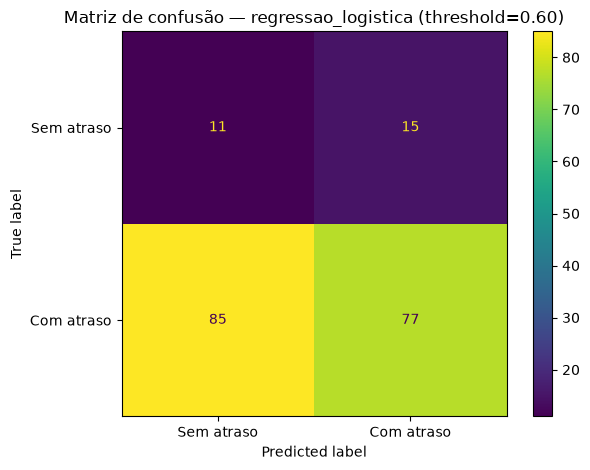

              precision    recall  f1-score   support

  Sem atraso       0.11      0.42      0.18        26
  Com atraso       0.84      0.48      0.61       162

    accuracy                           0.47       188
   macro avg       0.48      0.45      0.39       188
weighted avg       0.74      0.47      0.55       188



In [16]:
ConfusionMatrixDisplay.from_predictions(
    yc_test,
    test_pred,
    display_labels=["Sem atraso", "Com atraso"],
    values_format="d",
)
plt.title(
    f"Matriz de confusão — {best_clf_name} "
    f"(threshold={best_threshold:.2f})"
)
plt.tight_layout()
plt.show()

print(
    classification_report(
        yc_test,
        test_pred,
        target_names=["Sem atraso", "Com atraso"],
        zero_division=0,
    )
)


## 7. Curva de calibração

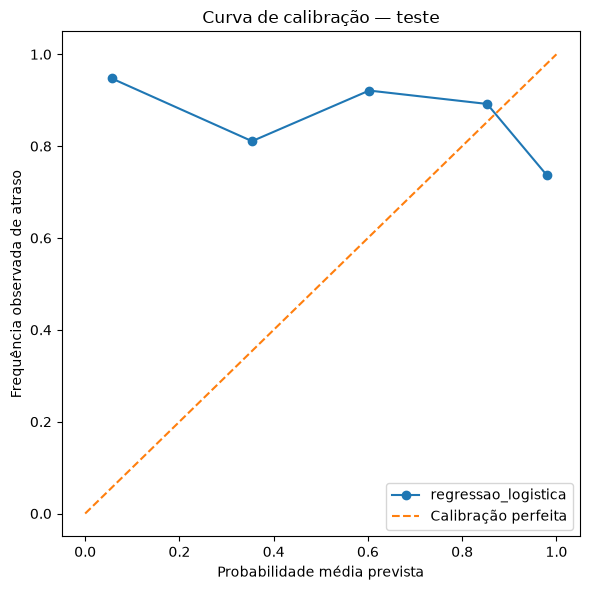

In [17]:
if pd.Series(yc_test).nunique() == 2:
    prob_true, prob_pred = calibration_curve(
        yc_test,
        test_proba,
        n_bins=5,
        strategy="quantile",
    )

    plt.figure(figsize=(6, 6))
    plt.plot(prob_pred, prob_true, marker="o", label=best_clf_name)
    plt.plot([0, 1], [0, 1], linestyle="--", label="Calibração perfeita")
    plt.xlabel("Probabilidade média prevista")
    plt.ylabel("Frequência observada de atraso")
    plt.title("Curva de calibração — teste")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 8. Avaliação complementar por contrato em horizonte ~90 dias

In [18]:
HORIZONTE_DIAS = 90

fixed_horizon = clf_test.copy()
fixed_horizon["dist_horizonte"] = (
    fixed_horizon["dias_restantes_prazo_vigente"] - HORIZONTE_DIAS
).abs()

fixed_horizon = (
    fixed_horizon
    .sort_values(["id_contrato", "dist_horizonte", "data_corte"])
    .groupby("id_contrato", as_index=False)
    .first()
)

X_fixed = fixed_horizon[features]
fixed_horizon["prob_atraso"] = best_clf.predict_proba(X_fixed)[:, 1]
fixed_horizon["pred_atraso"] = (
    fixed_horizon["prob_atraso"] >= best_threshold
).astype(int)

display(
    fixed_horizon[
        [
            "id_contrato",
            "data_corte",
            "dias_restantes_prazo_vigente",
            "target_atraso",
            "prob_atraso",
            "pred_atraso",
        ]
    ]
)


,id_contrato,data_corte,dias_restantes_prazo_vigente,target_atraso,prob_atraso,pred_atraso
0,158,2022-10-31,91,1.0000,0.1262,0
1,173,2024-07-31,80,1.0000,0.9996,1
2,201,2024-11-30,102,1.0000,0.8538,1
3,205,2024-09-30,86,1.0000,0.9230,1
4,248,2023-12-31,89,1.0000,0.5051,0
5,254,2025-05-31,83,0.0000,0.9764,1
6,283,2024-11-30,97,1.0000,0.6263,1
7,317,2024-11-30,84,1.0000,0.3012,0
8,342,2025-07-18,60,0.0000,0.5918,0
9,377,2025-04-29,90,1.0000,0.3915,0


## 9. Importância das features — validação

In [19]:
reg_perm = permutation_importance(
    best_reg,
    Xr_val,
    yr_val,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
)

reg_importance = (
    pd.DataFrame({
        "feature": features,
        "importance_mean": reg_perm.importances_mean,
        "importance_std": reg_perm.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
)

print("Importância — regressão")
display(reg_importance.head(15))


Importância — regressão


,feature,importance_mean,importance_std
2,dias_desde_os,98.2601,18.7500
5,qtd_aditivos_prazo,48.3478,6.8294
10,atraso_maximo_parcelas_dias,35.6835,5.5933
1,prazo_original_dias,25.1963,3.7053
6,dias_aditados_acumulados,14.2222,15.7519
7,qtd_aditivos_valor,4.7486,1.0791
8,pct_parcelas_concluidas_vs_previstas,3.0526,1.1379
0,valor_total_contrato,2.3795,1.0038
12,atraso_medio_parcelas_90d,0.0286,0.0135
13,qtd_parcelas_atrasadas_90d,-0.0511,0.1396


In [20]:
if yc_val.nunique() == 2:
    clf_perm = permutation_importance(
        best_clf,
        Xc_val,
        yc_val,
        scoring="roc_auc",
        n_repeats=10,
        random_state=RANDOM_STATE,
    )

    clf_importance = (
        pd.DataFrame({
            "feature": features,
            "importance_mean": clf_perm.importances_mean,
            "importance_std": clf_perm.importances_std,
        })
        .sort_values("importance_mean", ascending=False)
    )

    print("Importância — classificação")
    display(clf_importance.head(15))


Importância — classificação


,feature,importance_mean,importance_std
2,dias_desde_os,0.3121,0.0769
6,dias_aditados_acumulados,0.2869,0.0641
10,atraso_maximo_parcelas_dias,0.1116,0.0306
14,pct_financeiro_liberado,0.0757,0.0206
5,qtd_aditivos_prazo,0.0732,0.0278
7,qtd_aditivos_valor,0.0601,0.0425
18,classificacao_contrato,0.0598,0.0257
15,gap_prazo_financeiro,0.0574,0.0167
9,atraso_medio_parcelas_dias,0.0421,0.0168
12,atraso_medio_parcelas_90d,0.0412,0.0212


## 10. Sanity checks e salvamento

In [21]:
contract_split_counts = (
    model_data.groupby("id_contrato")["split_modelagem"].nunique()
)
assert contract_split_counts.max() == 1

forbidden = {
    "id_contrato",
    "numero_contrato",
    "status_final_controle",
    "data_conclusao_controle",
    "data_termino_vigente_final_controle",
    "target_dias_atraso",
    "target_atraso",
    "flag_apto_treino",
    "sample_weight_contrato",
    "sample_weight_contrato_raw",
    "split_modelagem",
    "split_contrato_temporal",
}
assert not (set(features) & forbidden)
assert clf_data["dias_restantes_prazo_vigente"].ge(0).all()

regression_metrics_df.to_csv(
    METRICS_DIR / "etapa2_regressao_comparacao.csv",
    index=False,
    encoding="utf-8-sig",
)

classification_metrics_050_df.to_csv(
    METRICS_DIR / "etapa2_classificacao_comparacao_threshold_050.csv",
    index=False,
    encoding="utf-8-sig",
)

pd.DataFrame([final_classification_metrics]).to_csv(
    METRICS_DIR / "etapa2_classificacao_teste_final.csv",
    index=False,
    encoding="utf-8-sig",
)

threshold_table.to_csv(
    METRICS_DIR / "etapa2_thresholds_validacao.csv",
    index=False,
    encoding="utf-8-sig",
)

horizon_reg.to_csv(
    METRICS_DIR / "etapa2_regressao_por_antecedencia.csv",
    index=False,
    encoding="utf-8-sig",
)

fixed_horizon[
    [
        "id_contrato", "data_corte",
        "dias_restantes_prazo_vigente",
        "target_atraso", "prob_atraso", "pred_atraso",
    ]
].to_csv(
    PREDICTIONS_DIR / "etapa2_classificacao_horizonte_90d.csv",
    index=False,
    encoding="utf-8-sig",
)

reg_importance.to_csv(
    METRICS_DIR / "etapa2_regressao_importancia_permutacao.csv",
    index=False,
    encoding="utf-8-sig",
)

if "clf_importance" in globals():
    clf_importance.to_csv(
        METRICS_DIR / "etapa2_classificacao_importancia_permutacao.csv",
        index=False,
        encoding="utf-8-sig",
    )

print("Sanity checks concluídos.")
print("Resultados salvos em:", ARTIFACTS_DIR)


Sanity checks concluídos.
Resultados salvos em: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\artifacts


# Critério para avançar para a próxima etapa

Considere Random Forest uma melhora real apenas se houver ganho **também no teste temporal**.

## Regressão
Procure:
- menor MAE;
- menor RMSE;
- maior R²;
- menor viés médio;
- melhora por faixa de antecedência.

## Classificação
Procure:
- ROC-AUC e PR-AUC melhores;
- balanced accuracy melhor;
- Brier menor;
- curva de calibração menos distorcida;
- melhora no horizonte de ~90 dias por contrato.

Se Random Forest melhorar apenas na validação, mas não no teste, o problema provavelmente está mais ligado a drift/amostra/features do que à complexidade do algoritmo.
